# Milestone 3 dan Final: EDA dan Insights

Isi notebook ini pada Pertemuan 6-10 dengan analisis temporal atau spasial, minimal 6 visualisasi interaktif Plotly/Altair, serta minimal 5 insight utama.

In [1]:
import polars as pl, duckdb, plotly.express as px, os

os.makedirs("../output/figures", exist_ok=True)
P = "../data/processed/data_clean.parquet"
lf = pl.scan_parquet(P)
wcols = [c for c in lf.collect_schema().names() if c.startswith("w_")]

def save(fig, name):
    fig.write_html(f"../output/figures/{name}.html")
    fig.show()

n_total = lf.select(pl.len()).collect().item()
print(f"Total dokumen bersih: {n_total:,} | kolom wilayah: {len(wcols)}")

Total dokumen bersih: 310,906 | kolom wilayah: 31


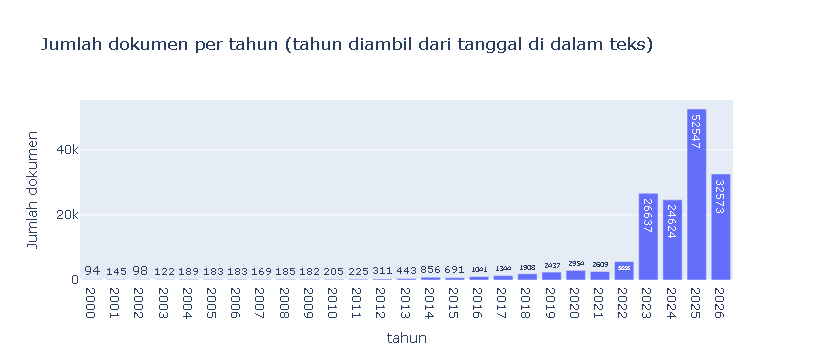

In [2]:
t = duckdb.sql(f"""
    SELECT tahun, count(*) AS n FROM '{P}'
    WHERE tahun IS NOT NULL GROUP BY 1 ORDER BY 1
""").pl()
fig1 = px.bar(t, x="tahun", y="n", text="n", title="Jumlah dokumen per tahun (tahun diambil dari tanggal di dalam teks)")
fig1.update_layout(xaxis=dict(dtick=1), yaxis_title="Jumlah dokumen")
save(fig1, "01_dokumen_per_tahun")

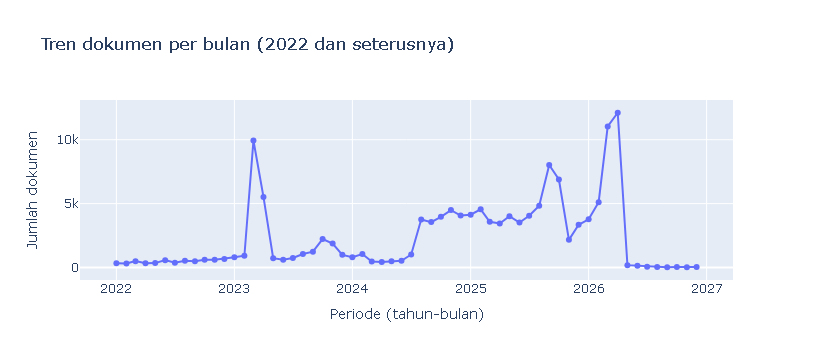

In [3]:
m = duckdb.sql(f"""
    SELECT tahun, bulan, count(*) AS n FROM '{P}'
    WHERE tahun >= 2022 AND bulan IS NOT NULL GROUP BY 1, 2 ORDER BY 1, 2
""").pl()
m = m.with_columns((pl.col("tahun").cast(pl.Utf8) + "-" + pl.col("bulan").cast(pl.Utf8).str.zfill(2)).alias("periode"))
fig2 = px.line(m, x="periode", y="n", markers=True, title="Tren dokumen per bulan (2022 dan seterusnya)")
fig2.update_layout(yaxis_title="Jumlah dokumen", xaxis_title="Periode (tahun-bulan)")
save(fig2, "02_tren_per_bulan")

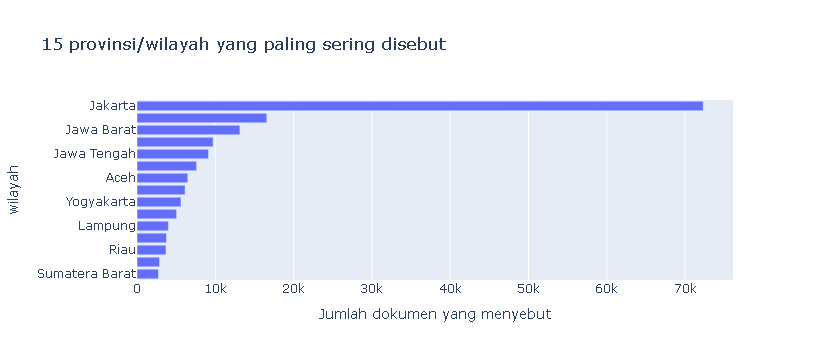

In [4]:
wil = (lf.select([pl.col(c).sum().alias(c[2:].replace("_", " ")) for c in wcols]).collect()
         .transpose(include_header=True, header_name="wilayah", column_names=["n"])
         .sort("n", descending=True))
fig3 = px.bar(wil.head(15), x="n", y="wilayah", orientation="h",
              title="15 provinsi/wilayah yang paling sering disebut")
fig3.update_layout(yaxis=dict(autorange="reversed"), xaxis_title="Jumlah dokumen yang menyebut")
save(fig3, "03_wilayah_teratas")

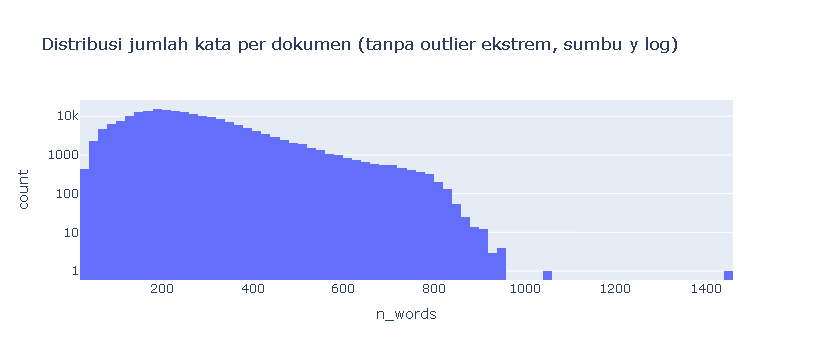

In [5]:
h = lf.filter(~pl.col("is_outlier_len")).select("n_words").collect()
h = h.sample(min(200_000, h.height), seed=42)
fig4 = px.histogram(h, x="n_words", nbins=80, log_y=True,
                    title="Distribusi jumlah kata per dokumen (tanpa outlier ekstrem, sumbu y log)")
save(fig4, "04_distribusi_panjang")

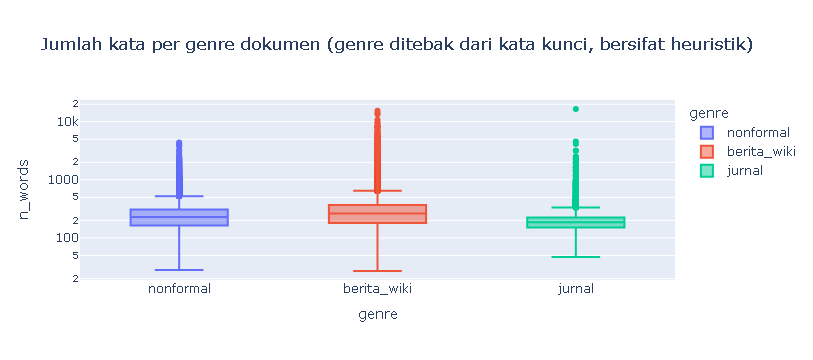

In [6]:
g = lf.select("genre", "n_words").collect()
g = g.sample(min(100_000, g.height), seed=42)
fig5 = px.box(g, x="genre", y="n_words", log_y=True, color="genre",
              title="Jumlah kata per genre dokumen (genre ditebak dari kata kunci, bersifat heuristik)")
save(fig5, "05_panjang_per_genre")

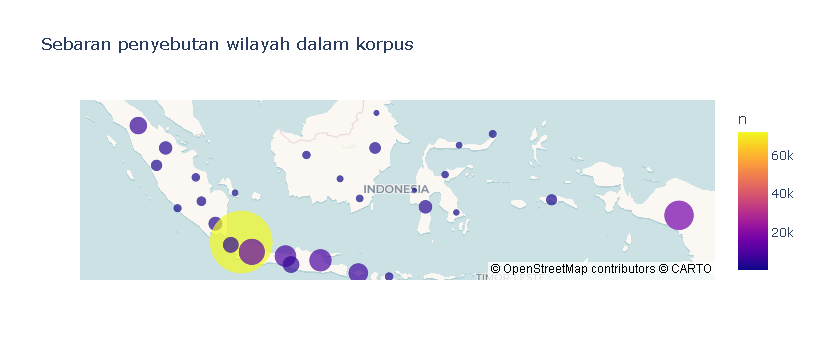

In [7]:
COORD = pl.DataFrame({
 "wilayah": ["Aceh","Sumatera Utara","Sumatera Barat","Riau","Jambi","Sumatera Selatan","Bengkulu","Lampung",
  "Bangka Belitung","Jakarta","Jawa Barat","Jawa Tengah","Yogyakarta","Jawa Timur","Banten","Bali",
  "Nusa Tenggara Barat","Nusa Tenggara Timur","Kalimantan Barat","Kalimantan Tengah","Kalimantan Selatan",
  "Kalimantan Timur","Kalimantan Utara","Sulawesi Utara","Sulawesi Tengah","Sulawesi Selatan",
  "Sulawesi Tenggara","Gorontalo","Sulawesi Barat","Maluku","Papua"],
 "lat": [4.7,2.1,-0.74,0.5,-1.6,-3.3,-3.8,-4.9,-2.7,-6.2,-6.9,-7.2,-7.8,-7.5,-6.4,-8.4,-8.65,-9.5,0.0,-1.7,
         -3.1,0.5,3.0,1.5,-1.4,-3.7,-4.1,0.7,-2.5,-3.2,-4.3],
 "lon": [96.75,99.5,100.8,101.45,103.6,104.0,102.3,105.0,106.4,106.85,107.6,110.0,110.4,112.5,106.1,115.2,
         117.4,122.0,111.5,113.9,115.3,116.4,116.5,124.8,121.4,120.0,122.2,122.4,119.2,129.0,138.1],
})
geo = wil.join(COORD, on="wilayah", how="inner")
try:
    fig6 = px.scatter_map(geo, lat="lat", lon="lon", size="n", color="n", hover_name="wilayah",
                          size_max=45, zoom=3.3, center={"lat": -2.5, "lon": 118},
                          title="Sebaran penyebutan wilayah dalam korpus")
except AttributeError:   # versi plotly lama
    fig6 = px.scatter_mapbox(geo, lat="lat", lon="lon", size="n", color="n", hover_name="wilayah",
                             size_max=45, zoom=3.3, center={"lat": -2.5, "lon": 118},
                             mapbox_style="open-street-map", title="Sebaran penyebutan wilayah dalam korpus")
save(fig6, "06_peta_wilayah")

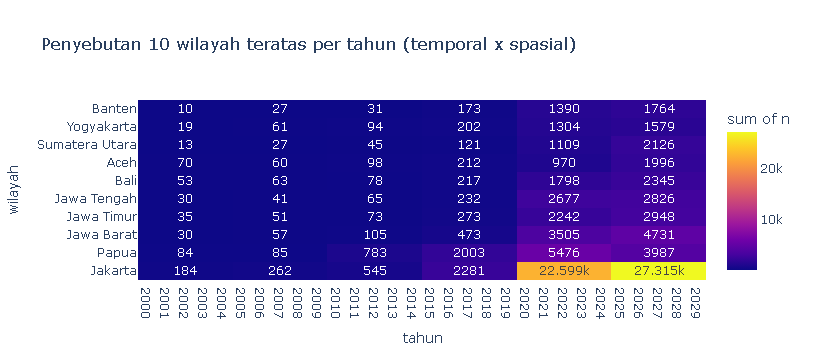

In [8]:
top10 = wil.head(10)["wilayah"].to_list()
rows = []
for w in top10:
    col = "w_" + w.replace(" ", "_")
    r = (lf.filter(pl.col(col) & pl.col("tahun").is_not_null())
           .group_by("tahun").agg(pl.len().alias("n"))
           .with_columns(pl.lit(w).alias("wilayah")).collect())
    rows.append(r)
hm = pl.concat(rows)
fig7 = px.density_heatmap(hm, x="tahun", y="wilayah", z="n", histfunc="sum", text_auto=True,
                          title="Penyebutan 10 wilayah teratas per tahun (temporal x spasial)")
fig7.update_layout(xaxis=dict(dtick=1))
save(fig7, "07_heatmap_wilayah_tahun")

In [9]:
tot_th = t["n"].sum()
th_top = t.sort("n", descending=True).row(0, named=True)
bl_top = m.sort("n", descending=True).row(0, named=True)
w5 = wil.head(5).with_columns((pl.col("n") / n_total * 100).round(1).alias("persen_dok"))
gen = lf.group_by("genre").agg(pl.len().alias("n"), pl.col("n_words").median().alias("median_kata")).collect()
gen = gen.with_columns((pl.col("n") / n_total * 100).round(1).alias("persen")).sort("n", descending=True)
med = lf.select(pl.col("n_words").median()).collect().item()
rata = lf.select(pl.col("n_words").mean()).collect().item()
p_outlier = lf.select(pl.col("is_outlier_len").mean()).collect().item() * 100

print("INSIGHT 1 (temporal):", f"{tot_th / n_total:.1%} dokumen punya tahun terdeteksi; terbanyak tahun {th_top['tahun']} ({th_top['n']:,} dokumen).")
print("INSIGHT 2 (lonjakan):", f"Bulan terpadat {bl_top['periode']} ({bl_top['n']:,} dokumen).")
print("INSIGHT 3 (spasial):", f"{w5['wilayah'][0]} paling sering disebut ({w5['n'][0]:,} dokumen, {w5['persen_dok'][0]}%), disusul {w5['wilayah'][1]} dan {w5['wilayah'][2]}.")
print("INSIGHT 4 (panjang):", f"median {med:,.0f} kata vs rata-rata {rata:,.0f} kata, distribusi miring ke kanan; {p_outlier:.1f}% dokumen outlier panjang.")
print("INSIGHT 5 (genre):")
print(gen)

INSIGHT 1 (temporal): 51.0% dokumen punya tahun terdeteksi; terbanyak tahun 2025 (52,547 dokumen).
INSIGHT 2 (lonjakan): Bulan terpadat 2026-04 (12,113 dokumen).
INSIGHT 3 (spasial): Jakarta paling sering disebut (72,318 dokumen, 23.3%), disusul Papua dan Jawa Barat.
INSIGHT 4 (panjang): median 240 kata vs rata-rata 287 kata, distribusi miring ke kanan; 2.2% dokumen outlier panjang.
INSIGHT 5 (genre):
shape: (3, 4)
┌─────────────┬────────┬─────────────┬────────┐
│ genre       ┆ n      ┆ median_kata ┆ persen │
│ ---         ┆ ---    ┆ ---         ┆ ---    │
│ str         ┆ u32    ┆ f64         ┆ f64    │
╞═════════════╪════════╪═════════════╪════════╡
│ berita_wiki ┆ 192459 ┆ 264.0       ┆ 61.9   │
│ nonformal   ┆ 87910  ┆ 229.0       ┆ 28.3   │
│ jurnal      ┆ 30537  ┆ 187.0       ┆ 9.8    │
└─────────────┴────────┴─────────────┴────────┘
